# 🟩 H&M 고객 표본 분석 보고서  

## 🟢 목표와 읽는 방법  

고객 표본의 구매 기록·상품 설명·실제 이미지로 전처리, 통계, 고객 분류, 시각화를 한 흐름으로 실행한다. 각 코드 셀을 위에서 아래로 실행한다. 이미 저장된 출력도 확인할 수 있다.  

원본 파일·고객별 표는 공개하지 않고, 이 노트북에는 구조·상품 정보 일부·집계만 표시한다. 보고서의 데이터 기간은 과거 H&M 대회 관측 기간이며 현재 영업 상태를 설명하지 않는다.  

## 🟢 맥락과 방법  

입력: `data/sample/transactions.csv`, `data/sample/articles.csv`, `data/raw/images`. 표본 추출은 고정 SHA-256 순서로 고른 고객의 전체 구매 이력을 보존한 방식이다. 상품 표는 article_id로 다대일 연결한다. 데이터 출처는 [H&M 공식 대회](https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations/data)다. 파일 비교값은 실행 후 `data/processed/analysis_summary.json`에서 확인한다.  

### 🟡 해석에 영향을 주는 가정  

- 한 행은 구매 기록이다. 반복 행은 여러 번 구매일 수 있어 보존한다.  
- `order_date`는 원본 `t_dat`, `amount`는 원본 `price`다. 주문 번호나 수량을 만들지 않는다.  
- Frequency는 구매 행 수다. Monetary는 원본 가격 합계이며 통화 단위는 확인되지 않았다.  
- Recency 기준일은 마지막 거래일이다. “최근”은 이 과거 표본 안에서 상대적인 표현이다.  
- 이미지 없는 거래는 보존한다. 상품별 이미지·가격 관계는 상품당 한 행에서 계산한다.  
- 설명 길이 결측치는 상품군 중앙값으로 대치하고 대치 여부를 별도로 표시한다.  
- IQR 경계 대치는 비교용 사본에만 적용한다. 고객별 원래 구매 금액은 유지한다.  
- 그룹은 최근 구매와 빈도·금액 중앙값 기준으로 나누며 동일한 값의 고객은 같은 순위 점수를 받는다.  

환경 준비와 각 계산의 뜻은 `_practice/02_분석_시작`의 단계별 문서를 따른다. 노트북이 저장된 `notebooks`에서 실행해도 프로젝트 최상위를 찾아 실행한다.  

<br>

## 🟢 1. 환경과 분석 도구 준비  

In [43]:
import sys  # 프로젝트 분석 코드를 가져올 위치를 지정한다.
from pathlib import Path  # 프로젝트와 데이터 위치를 찾는다.


# IPython.display 그저 print를 markdown 문법으로 더 보기 좋게 하려는 것 뿐이다.
from IPython.display import display, Markdown  # 집계와 한국어 해석을 노트북에 표시한다.
    # IPython - Jupyter Notebook에서 자주 쓰이는 Python 실행 환경
    # display - Pandas DataFrame을 노트북에서 표 형태로 예쁘게 보여준다.
    # Markdown - 문자열을 Markdown 문법으로 해석해서 제목, 굵게, 목록 등으로 표시


# 어떤 환경에서도 data, src 폴더가 있는 root directory를 찾을 수 있도록 만든 코드
root = Path.cwd()  # 현재 노트북 실행 위치부터 확인한다.
root = root if (root / 'src/pipeline.py').is_file() else root.parent  # notebooks에서 실행해도 최상위를 찾는다.
assert (root / 'src/pipeline.py').is_file(), '프로젝트 최상위 또는 notebooks에서 실행해.'  # 잘못된 폴더에서 진행하지 않는다.
sys.path.insert(0, str(root))  # 프로젝트 코드를 가져올 수 있게 한다.


# src (소스코드를 만들어놓고, 주피터노트북에서 사용한다.)
import importlib  # 주피터가 기억하는 이전 코드 대신 수정한 파일을 다시 읽는다.
import src.pipeline as pipeline_module  # 고객 분류 코드 파일을 가져온다.
import src.reporting as reporting_module  # 결과 설명 코드 파일을 가져온다.
import src.charts as charts_module  # 그래프 코드 파일을 가져온다.
importlib.reload(pipeline_module)  # 최신 고객 그룹 이름을 읽는다.
importlib.reload(reporting_module)  # 최신 이름에 맞는 설명을 읽는다.
importlib.reload(charts_module)  # 최신 영어 라벨과 그래프 모양을 읽는다.
from src.pipeline import DataAnalyzer  # 실제 CLI와 같은 분석 클래스를 사용한다.
from src.reporting import business_insights, markdown_table, statistics_interpretations, MISSING_VALUE_RATIONALE, OUTLIER_RATIONALE  # 같은 집계 해석을 재사용한다.
from src.charts import build_charts  # 같은 코드로 그래프를 만든다.


# numpy
import numpy as np  # 검증에 배열 연산을 사용한다.


# matplotlib
import matplotlib.pyplot as plt  # 그래프 표시와 메모리 정리를 담당한다.
get_ipython().run_line_magic('matplotlib', 'inline')  # 그래프를 외부 창 대신 노트북 출력에 넣는다.
_ = plt.ioff()  # 그림 여섯 개가 자동 중복 표시되지 않게 하고 반환값도 출력하지 않는다.

<br><br><br>

## 🟢 2. 분석 실행과 관측 결과 요약  

- 최소 거래 수·상품 연결·가격·날짜를 확인하고, 실제 결측치를 대치한 뒤 이미지 해석과 고객 분류를 진행한다.  
- 이 셀에서는 고객별 거래를 출력하지 않는다.  

In [44]:
# 🔥 pipeline main 함수인 run 실행
analyzer = DataAnalyzer(root / 'data/sample', root / 'data/raw/images').run()  # 준비한 실제 표본을 한 번 분석한다.

audit = analyzer.audit  # 같은 실행의 결과만 해석에 사용한다.

# 여기서 display(Markdown 그저 print를 보기 좋게 하려는 것 뿐이다.
display(Markdown(f"고객 **{audit['customers']:,}명**, 거래 **{audit['rows']:,}행**, 상품 **{audit['products']:,}개**, 실제 이미지 **{audit['images']['decoded_products']}개**를 분석했다. 관측 기간은 **{audit['date_min']}~{audit['date_max']}**다. 고객 그룹은 **{audit['rfm']['segment_count']}개**다."))  # 집계 근거를 먼저 보여 준다.
display(Markdown(f"설명 누락 상품 {audit['imputation']['missing_products']}개, 영향 거래 {audit['imputation']['filled_transaction_rows']}행을 표시해 대치했다. 사진 연결 거래는 {audit['images']['covered_transaction_rows']}행({audit['images']['coverage_fraction']:.2%})이므로 이미지 결과를 전체 거래로 일반화하지 않는다."))  # 결측치·이미지 분석 범위를 요약한다.

고객 **500명**, 거래 **11,927행**, 상품 **7,912개**, 실제 이미지 **100개**를 분석했다. 관측 기간은 **2018-09-20~2020-09-22**다. 고객 그룹은 **4개**다.

설명 누락 상품 33개, 영향 거래 47행을 표시해 대치했다. 사진 연결 거래는 156행(1.31%)이므로 이미지 결과를 전체 거래로 일반화하지 않는다.

<br><br><br>

## 🟢 3. 모든 과정을 거친 analyzer 변수의 데이터 구조와 안전한 미리보기  

- `info()`는 컬럼 자료형과 누락 규모, `head()`는 형태, `describe()`는 숫자 분포를 보여 준다.  
- 미리보기에서는 고객 번호·날짜·금액을 함께 출력하지 않는다.  

In [45]:
print(analyzer.schema_info())  # 고객 번호 값 없이 자료형과 개수만 확인한다.
# 🔥 결측치, 이상치 등등의 모든 과정을 거치고 추가적으로 피처 엔지니어링되어 열로 merge된 정보를 볼 수 있다.
    # `add_image_features()`: `image_mean`, `image_std` 열로 연결된 것을 확인할 수 있다.
    # `add_text_features()`: 상품명 길이 `product_name_length`와 단어 수 `product_name_words` 열로 연결된 것을 확인할 수 있다.

print('\n')

display(analyzer.safe_preview())  # 상품 정보만 다섯 행 이내로 확인한다.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11927 entries, 0 to 11926
Data columns (total 42 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   t_dat                           11927 non-null  object        
 1   customer_id                     11927 non-null  string        
 2   article_id                      11927 non-null  object        
 3   price                           11927 non-null  float64       
 4   sales_channel_id                11927 non-null  int64         
 5   order_date                      11927 non-null  datetime64[ns]
 6   amount                          11927 non-null  float64       
 7   product_code                    11927 non-null  int64         
 8   prod_name                       11927 non-null  object        
 9   product_type_no                 11927 non-null  int64         
 10  product_type_name               11927 non-null  object        
 11  pr

,product_group_name,prod_name,product_name_length
0,Garment Lower body,PLOPP tights,12.0
1,Garment Lower body,SUPREME TIGHTS,14.0
2,Garment Lower body,Shaping Skinny H.W,18.0
3,Garment Upper body,Woody(1),8.0
4,Garment Upper body,Annette,7.0


<br><br><br>

## 🟢 4. 결측치 대치와 이상치 기준  


### 🟡 결측치 처리  

> `결측치`는 빈값을 의미하며, 대치할 값을 채운다.  

#### 왜 전체 평균이 아니라 그룹별 중앙값을 썼는가?  
- 상품 종류마다 가격 수준이 다르기 때문에 전체 평균으로 채우면 각 상품군의 특성이 왜곡될 수 있다.  

- 또한 가격에는 이상치가 존재할 수 있으므로 평균보다 이상치 영향을 덜 받는 중앙값을 사용했다.  

- 상품이 여러 번 팔려도 대치 통계에는 상품당 한 번만 넣는다.  


### 🟡 이상치  

> `이상치`는 보통의 값들에 비해 지나치게 차이가 나는 값을 의미하며, 튀는 통계를 방지하기 위해 제외할 수 있다.  

- IQR 탐지 뒤 무엇을 하는가:  
    - IQR 탐지의 목적은 극단적인 가격이 평균과 분포에 주는 영향을 살펴볼 구매를 찾는 것이다.  
    - 정규분포를 필수로 가정하지 않지만 비대칭·긴 꼬리 분포에서는 정상 고가 구매도 표시될 수 있다.  
    - 원본과 경계값에 맞춘 사본의 박스플롯을 비교하며, 구매 행은 삭제하지 않는다.  
    - 사본의 큰 가격을 줄였다는 이유로 실제 고객 금액까지 줄이지 않도록 RFM은 원래 가격을 사용한다.  



In [46]:
display(Markdown(f"설명 길이 대치: 상품 {audit['imputation']['missing_products']}개, 거래 {audit['imputation']['filled_transaction_rows']}행, 대치 후 숫자 누락 {audit['imputation']['remaining']}개. 전체 상품 통계로 보완한 상품은 {audit['imputation']['global_fallback_products']}개다."))  # 대치의 실제 규모를 설명한다.
display(Markdown(f"IQR = Q3 - Q1 = {audit['outliers']['iqr']:.6f}. 배율 {audit['outliers']['factor']}의 하한 {audit['outliers']['lower']:.6f}, 상한 {audit['outliers']['upper']:.6f} 밖은 {audit['outliers']['count']}행({audit['outliers']['count'] / audit['rows']:.2%})이다. 경계 밖이라는 사실만으로 잘못된 구매라고 판단하지 않는다."))  # 범위 계산과 해석 한계를 설명한다.

display(Markdown("**그룹 중앙값을 선택한 이유와 한계:** " + MISSING_VALUE_RATIONALE))  # 대치 방법의 선택 근거를 보여 준다.
display(Markdown("**IQR 탐지 뒤 무엇을 하는가:** " + OUTLIER_RATIONALE))  # 탐지 목적과 전후 비교·원본 유지의 연결을 설명한다.

설명 길이 대치: 상품 33개, 거래 47행, 대치 후 숫자 누락 0개. 전체 상품 통계로 보완한 상품은 0개다.

IQR = Q3 - Q1 = 0.018644. 배율 1.5의 하한 -0.012729, 상한 0.061847 밖은 512행(4.29%)이다. 경계 밖이라는 사실만으로 잘못된 구매라고 판단하지 않는다.

**그룹 중앙값을 선택한 이유와 한계:** 상품 종류마다 설명 길이가 다를 수 있어 전체 평균 대신 같은 상품군의 대표값을 사용했다. 중앙값은 매우 긴 설명 몇 개의 영향을 평균보다 덜 받으므로 이번 기본 전략으로 골랐다. 상품당 한 번 계산하고, 해당 상품군 전체가 비었다면 전체 상품의 중앙값으로 보완한다. 대치는 같은 값이 반복돼 그룹 안의 퍼짐을 줄이거나, 결측 원인이 편향됐을 때 그룹 차이·상관관계를 왜곡할 수 있다. 그래서 원래 결측 여부를 남겼으며, 평균 대치와 비교해 중앙값이 더 우수하다고 검증한 것은 아니다.

**IQR 탐지 뒤 무엇을 하는가:** IQR 탐지의 목적은 극단적인 가격이 평균과 분포에 주는 영향을 살펴볼 구매를 찾는 것이다. 정규분포를 필수로 가정하지 않지만 비대칭·긴 꼬리 분포에서는 정상 고가 구매도 표시될 수 있다. 원본과 경계값에 맞춘 사본의 박스플롯을 비교하며, 구매 행은 삭제하지 않는다. 사본의 큰 가격을 줄였다는 이유로 실제 고객 금액까지 줄이지 않도록 RFM은 원래 가격을 사용한다.

<br><br><br>

## 🟢 5. 주요 숫자의 분포 요약  

- 표의 단위는 원본 가격과 문자 수, 0~1 픽셀 통계다.  
- 이미지 컬럼의 count는 사진 수가 아니라 사진이 연결된 구매 행 수다.  
- 50%는 중앙값, 25%·75%는 사분위수다.  

앤스컴 콰르텟 이라는 기술 통계가 있음  

In [47]:
# 🔥 summary_statistics 함수 사용
display(analyzer.summary_statistics().rename_axis('feature').round(6))  # 과제에서 요구한 describe 기반 요약 통계를 표시한다.

prices = analyzer.df['price']  # 원본 가격 분포를 선택한다.

# 🔥 
for interpretation in statistics_interpretations(analyzer):  # 다섯 변수의 실제 숫자와 해석을 하나씩 꺼낸다.
    display(Markdown(interpretation))  # 보고서와 같은 근거·시사점·대상 범위를 표시한다.

,count,mean,std,min,25%,50%,75%,max
feature,,,,,,,,
price,11927.0,0.027422,0.018639,0.001000,0.015237,0.025407,0.033881,0.303390
product_name_length,11927.0,15.285487,6.209969,1.000000,11.000000,15.000000,20.000000,30.000000
description_length,11927.0,133.129622,58.802873,15.000000,91.000000,126.000000,169.000000,484.000000
image_mean,156.0,0.793479,0.089309,0.487344,0.751754,0.801651,0.867692,0.913596
image_std,156.0,0.199644,0.109289,0.013766,0.097780,0.226713,0.289747,0.408491


- **구매가격 (`price`)**: 구매 11,927행에서 평균 0.027422, 중앙값 0.025407, 표준편차 0.018639, Q1 0.015237, Q3 0.033881 (원본 가격 단위)다. 평균과 중앙값의 차이는 큰 가격의 영향을 살펴볼 단서다. 통화·할인 정보를 확인하기 전 비싸다거나 이익이 높다고 단정하지 않는다. 구매 행 기준이므로 많이 팔린 상품은 반복 포함된다. 상품마다 한 번 계산하는 상관분석과 구분한다.

- **상품명 길이 (`product_name_length`)**: 구매 11,927행에서 평균 15.285487, 중앙값 15.000000, 표준편차 6.209969, Q1 11.000000, Q3 20.000000 (글자)다. 25~75% 지점의 길이로 구매에 연결된 상품명의 대표 범위를 읽는다. 이름 길이가 가격과 관련되는지는 상품 단위 상관분석으로 따로 확인한다. 구매 행 기준이므로 많이 팔린 상품은 반복 포함된다. 상품마다 한 번 계산하는 상관분석과 구분한다.

- **설명 길이 (`description_length`)**: 구매 11,927행에서 평균 133.129622, 중앙값 126.000000, 표준편차 58.802873, Q1 91.000000, Q3 169.000000 (글자)다. 상품군 중앙값으로 채운 설명 길이도 포함한다. 이 퍼짐은 원래 관측값만의 분포가 아니므로 대치 전 분포와 같다고 해석하지 않는다. 구매 행 기준이므로 많이 팔린 상품은 반복 포함된다. 상품마다 한 번 계산하는 상관분석과 구분한다.

- **사진 색상 평균 (`image_mean`)**: 구매 156행에서 평균 0.793479, 중앙값 0.801651, 표준편차 0.089309, Q1 0.751754, Q3 0.867692 (0~1 색상 값)다. 25~75% 지점으로 사진의 평균 색상 수준이 모인 범위를 읽는다. 배경·촬영 방식의 영향도 있어 상품 자체의 성질이나 전체 상품의 특징으로 단정하지 않는다. 사진이 있는 구매 행 기준이며 같은 사진이 반복 구매에 여러 번 포함된다. 서로 다른 사진 수나 전체 구매 분포와 구분한다.

- **사진 안 색상 퍼짐 (`image_std`)**: 구매 156행에서 평균 0.199644, 중앙값 0.226713, 표준편차 0.109289, Q1 0.097780, Q3 0.289747 (0~1 색상 값)다. 이 피처가 큰 사진은 사진 안 색상 숫자의 차이가 큰 편이다. 이 행의 표준편차는 사진별 퍼짐 값들이 구매 행들 사이에서 다시 얼마나 다른지를 나타낸다. 사진이 있는 구매 행 기준이며 같은 사진이 반복 구매에 여러 번 포함된다. 서로 다른 사진 수나 전체 구매 분포와 구분한다.

<br><br><br>

## 🟢 6. 그래프를 위한 공통 틀 준비  

차트의 제목·축·색상은 공통 함수에서 관리한다. 영어 축 이름은 폰트 환경이 달라도 깨지지 않게 선택했고, 각 차트의 한국어 해석은 바로 아래에 둔다.  

In [48]:
import importlib  # 커널을 끄지 않아도 수정한 파일을 다시 읽는 도구다.
import src.pipeline as pipeline_module  # 그룹 이름을 정의한 파일을 선택한다.
import src.charts as charts_module  # 그래프를 만드는 파일을 선택한다.
import src.reporting as reporting_module  # 그룹별 설명을 만드는 파일을 선택한다.
importlib.reload(pipeline_module)  # 메모리에 남은 옛 그룹 이름을 최신 이름으로 갱신한다.
importlib.reload(charts_module)  # 메모리에 남은 옛 그래프 함수를 최신 함수로 갱신한다.
importlib.reload(reporting_module)  # 이후 설명에도 최신 이름을 사용한다.
business_insights = reporting_module.business_insights  # 아래의 고객 그룹 설명도 최신 함수로 연결한다.
_ = pipeline_module.DataAnalyzer.calculate_rfm(analyzer, reference_date=audit['rfm']['reference_date'], frequency=audit['rfm']['frequency_unit'])  # 기존 기준일과 빈도 단위로 최신 이름의 고객 그룹을 다시 만든다.
figures = charts_module.build_charts(analyzer, root / 'reports/figures')  # 최신 라벨의 그래프 여섯 개를 만들어 기존 PNG를 덮어쓴다.


### 🟡 6-1. 가격 히스토그램: 어느 가격 구간에 구매가 몰렸는가  

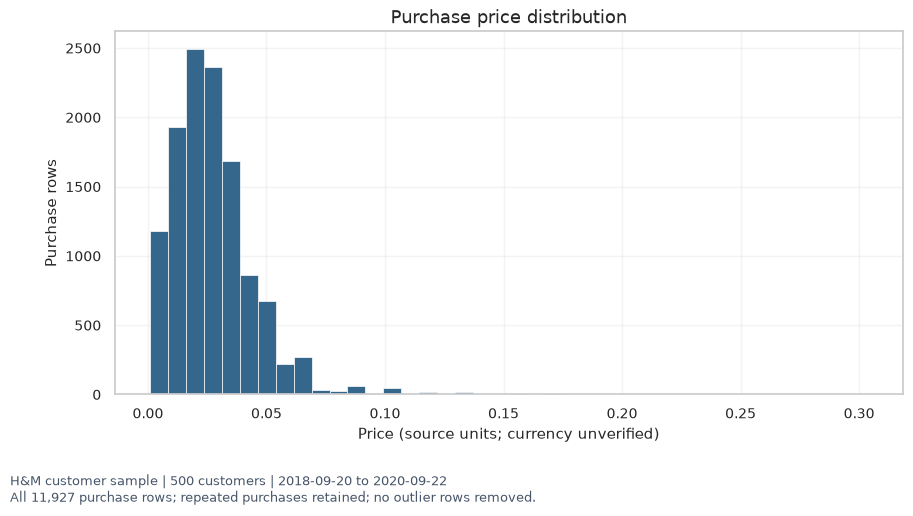

구매 11,927행의 가격 중앙값은 0.025407, 위쪽 사분위수는 0.033881다. 빈도는 구매 행 수이고 금액은 원본 단위다. 고객 500명의 표본 분포이므로 전체 회사의 가격 전략으로 단정하지 않는다.

In [49]:
display(figures['01_price_histogram'])  # 전체 거래의 가격 분포를 표시한다.
plt.close(figures['01_price_histogram'])  # 이미 표시한 그림 창의 메모리를 정리한다.
display(Markdown(f"구매 {len(prices):,}행의 가격 중앙값은 {prices.median():.6f}, 위쪽 사분위수는 {prices.quantile(0.75):.6f}다. 빈도는 구매 행 수이고 금액은 원본 단위다. 고객 500명의 표본 분포이므로 전체 회사의 가격 전략으로 단정하지 않는다."))  # 분모와 수치 해석을 붙인다.

### 🟡 6-2. 박스플롯: 가격 경계 대치가 분포를 어떻게 바꾸는가  

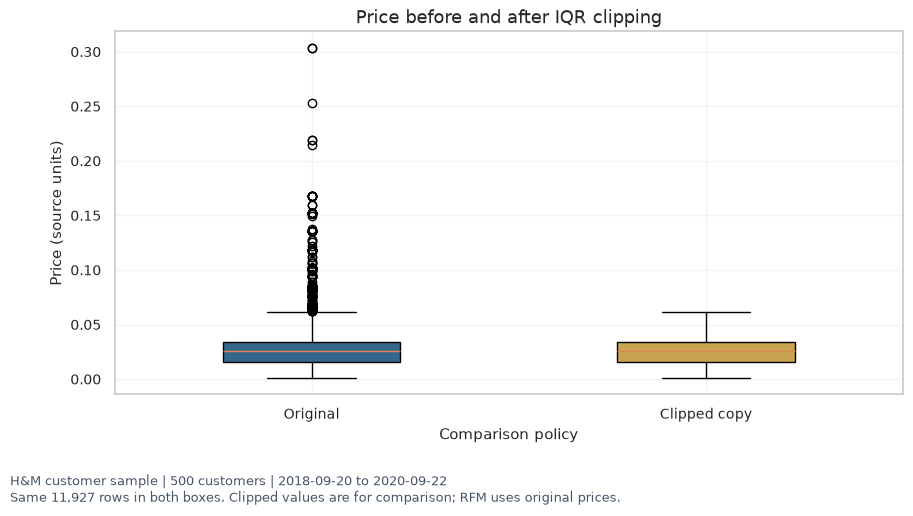

상한은 0.061847, 경계 밖 기록은 512행이다. 두 상자는 같은 11,927행을 사용한다. 원본 금액을 보존하므로 시각화용 처리로 고객의 구매 금액이 줄어들지는 않는다.

In [50]:
display(figures['02_price_boxplot'])  # 원본과 경계 대치 사본을 같은 축에서 비교한다.
plt.close(figures['02_price_boxplot'])  # 그림 메모리를 정리한다.
display(Markdown(f"상한은 {audit['outliers']['upper']:.6f}, 경계 밖 기록은 {audit['outliers']['count']}행이다. 두 상자는 같은 {audit['rows']:,}행을 사용한다. 원본 금액을 보존하므로 시각화용 처리로 고객의 구매 금액이 줄어들지는 않는다."))  # 전후 비교의 뜻을 명확히 한다.

### 🟡 6-3. 막대그래프: 고객 그룹별로 몇 명인가 (RFM)  

- 최근 여부는 Recency 중앙값 이하  
- 고가치는 Frequency·Monetary가 모두 각각의 중앙값 이상이라는 뜻이다.  
- 신규 회원·실제 이탈 여부를 관측한 분류는 아니다.  

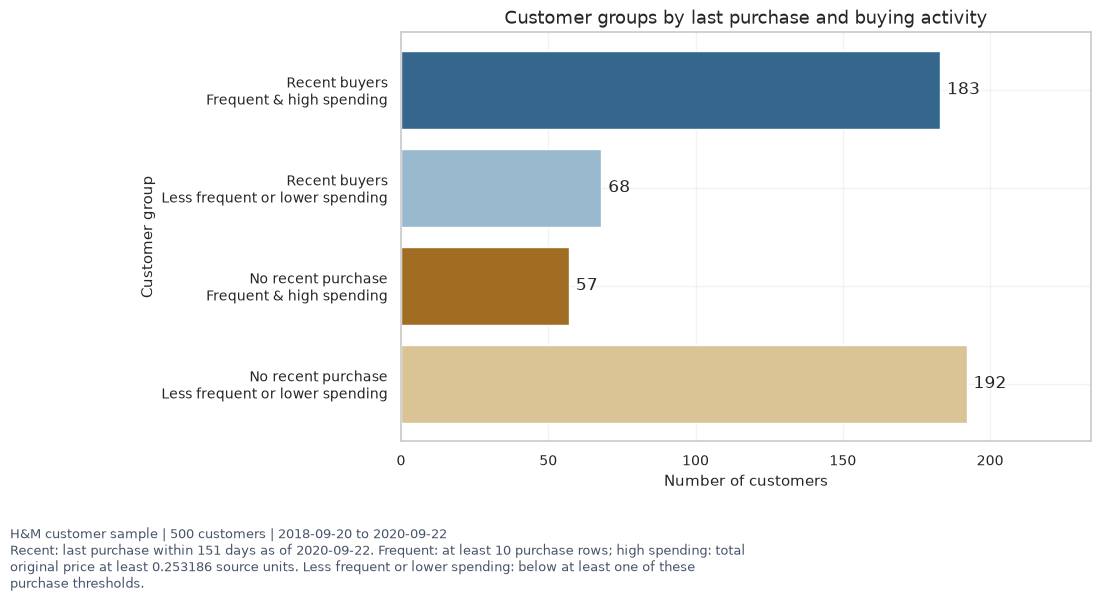

,customers,mean_recency,mean_frequency,mean_monetary,total_monetary,customer_share,monetary_share
segment,,,,,,,
Recent buyers / Frequent & high spending,183,46.7705,51.4863,1.4330,262.2428,0.366,0.8018
Recent buyers / Less frequent or lower spending,68,65.8824,4.7500,0.1205,8.1942,0.136,0.0251
No recent purchase / Frequent & high spending,57,342.4035,24.3333,0.6390,36.4233,0.114,0.1114
No recent purchase / Less frequent or lower spending,192,454.3385,4.1406,0.1052,20.2041,0.384,0.0618


Recency 기준은 151.0일, Frequency 기준은 10.0행, Monetary 기준은 0.253186다. 표본 안에서의 상대적 분류이므로 기준을 바꾸면 그룹도 달라질 수 있다.

In [51]:
display(figures['03_segment_bar'])  # 서로 겹치지 않는 고객 그룹을 비교한다.
plt.close(figures['03_segment_bar'])  # 그림 메모리를 정리한다.
display(analyzer.segment_summary().round(4))  # 고객 식별자 없는 정확한 값도 제공한다.
display(Markdown(f"Recency 기준은 {audit['rfm']['recency_median_days']:.1f}일, Frequency 기준은 {audit['rfm']['frequency_median']:.1f}행, Monetary 기준은 {audit['rfm']['monetary_median']:.6f}다. 표본 안에서의 상대적 분류이므로 기준을 바꾸면 그룹도 달라질 수 있다."))  # 실제 분류 기준을 제시한다.

### 🟡 6-4. 히트맵: 변수 사이 관계가 얼마나 큰가  

- 상관계수 r은 `-1 ~ 1` 사이의 숫자야.  
    - `1`에 가까우면 함께 커지는 직선적인 경향  
    - `-1`에 가까우면 한쪽이 커질 때 다른 쪽이 작아지는 경향,  
    - `0`에 가까우면 그런 직선적인 경향이 약하다는 뜻이야.  

- 상품당 한 행으로 계산한다.  
- 이미지가 없는 상품은 해당 변수 쌍에서 제외한다.  
- 글 길이에는 대치 값이 포함된다.  

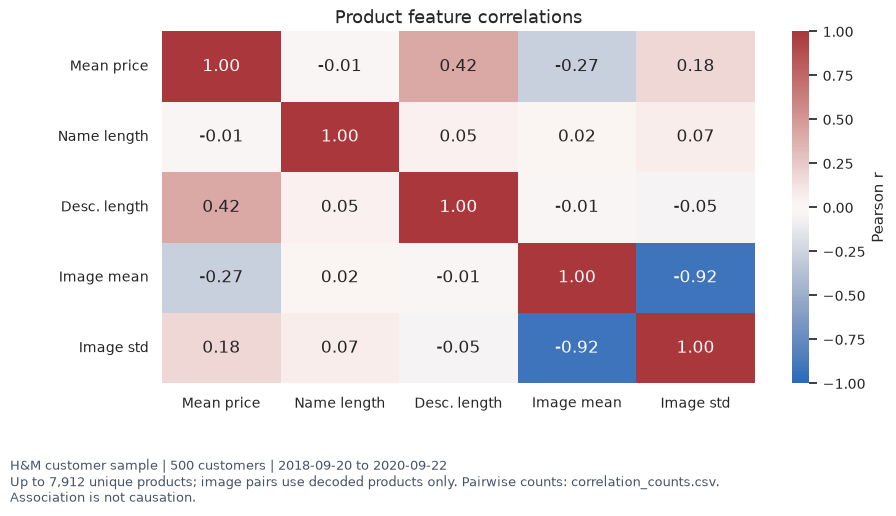

,left,right,n_products,pearson_r
0,mean_purchase_price,product_name_length,7912,-0.0067
1,mean_purchase_price,image_mean,100,-0.2740
2,image_mean,image_std,100,-0.9169


,product_name_length,description_length,image_mean,image_std,mean_purchase_price
product_name_length,7912,7912,100,100,7912
description_length,7912,7912,100,100,7912
image_mean,100,100,100,100,100
image_std,100,100,100,100,100
mean_purchase_price,7912,7912,100,100,7912


mean_purchase_price와 product_name_length: 상품 7,912개에서 r=-0.0067다. 부호는 선형 관계 방향이고 |r|은 그 크기다. 0에 가까우면 선형 관계 근거가 약하다. 큰 값이라도 원인이나 추천 효과를 입증하지는 않는다.

mean_purchase_price와 image_mean: 상품 100개에서 r=-0.2740다. 부호는 선형 관계 방향이고 |r|은 그 크기다. 0에 가까우면 선형 관계 근거가 약하다. 큰 값이라도 원인이나 추천 효과를 입증하지는 않는다.

image_mean와 image_std: 상품 100개에서 r=-0.9169다. 부호는 선형 관계 방향이고 |r|은 그 크기다. 0에 가까우면 선형 관계 근거가 약하다. 큰 값이라도 원인이나 추천 효과를 입증하지는 않는다.

In [52]:
display(figures['04_correlation_heatmap'])  # 관계의 부호와 크기를 표시한다.
plt.close(figures['04_correlation_heatmap'])  # 그림 메모리를 정리한다.

# 
display(analyzer.correlations().round(4))  # 최소 두 쌍 이상의 계수와 상품 수를 표시한다.


# 
display(analyzer.correlation_counts())  # 히트맵의 모든 칸이 어떤 분모를 쓰는지 확인한다.
# correlation_counts 이것도 내장함수같은 존재인가???


for pair in analyzer.correlations().itertuples(index=False):  # 해석은 실제 계산한 계수에 근거한다.
    display(Markdown(f"{pair.left}와 {pair.right}: 상품 {pair.n_products:,}개에서 r={pair.pearson_r:.4f}다. 부호는 선형 관계 방향이고 |r|은 그 크기다. 0에 가까우면 선형 관계 근거가 약하다. 큰 값이라도 원인이나 추천 효과를 입증하지는 않는다."))  # 수치·해석·한계를 함께 표시한다.

#### ⚫️ 나온 결과에 대해서 상관관계를 해석해보자면  

| 실제로 비교한 한 쌍 | 비교 대상 | 상관계수 | 쉬운 해석 |  
| --- | --- | --- | --- |
| 상품별 평균 구매가격 ↔ 상품명 글자 수 | 상품 7,912개 | 약 -0.0067 | 거의 0이므로 이름이 길수록 비싸거나 싸다는 직선적인 관계가 거의 안 보임 |  
| 상품별 평균 구매가격 ↔ 이미지 색상 평균 | 사진 있는 상품 100개 | 약 -0.2740 | 이 표본에서는 반대 방향의 경향이 일부 보이지만, 색상 평균만으로 가격을 설명할 수 있다고 단정할 수 없음 |  
| 이미지 색상 평균 ↔ 이미지 색상 표준편차 | 사진 있는 상품 100개 | 약 -0.9169 | 이 사진들에서는 평균 색상 값이 높은 쪽의 색상 숫자 퍼짐이 작은 경향이 강하게 보임 |  

<br>

### 🟡 6-5. 산점도: 이미지 밝기와 관측 구매 가격이 함께 변하는가  

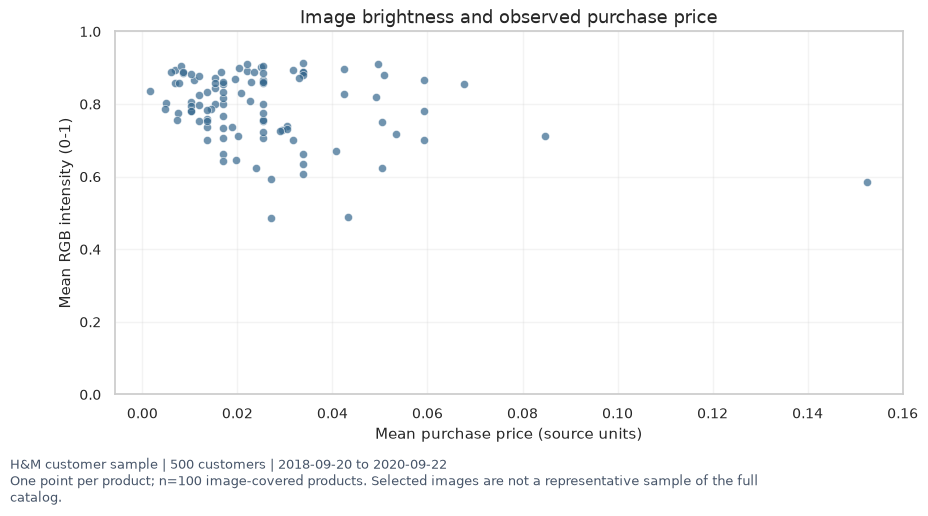

이미지 있는 상품 100개의 계수는 r=-0.2740다. 구매가 많은 상품을 여러 점으로 중복 표시하지 않았다. 이미지 배경·촬영 조건·상품군의 영향을 분리하지 않았으므로 밝기가 가격을 결정한다고 해석할 수 없다.

In [53]:
display(figures['05_image_price_scatter'])  # 이미지 있는 상품당 점 하나를 표시한다.
plt.close(figures['05_image_price_scatter'])  # 그림 메모리를 정리한다.
pair = analyzer.correlations().iloc[1]  # 이미지 밝기와 구매 가격의 실제 결과를 읽는다.
display(Markdown(f"이미지 있는 상품 {int(pair['n_products'])}개의 계수는 r={pair['pearson_r']:.4f}다. 구매가 많은 상품을 여러 점으로 중복 표시하지 않았다. 이미지 배경·촬영 조건·상품군의 영향을 분리하지 않았으므로 밝기가 가격을 결정한다고 해석할 수 없다."))  # 관측 단위와 교란 가능성을 설명한다.

### 🟡 6-6. 라인차트: 월별 표본 구매 금액이 어떻게 달라지는가  

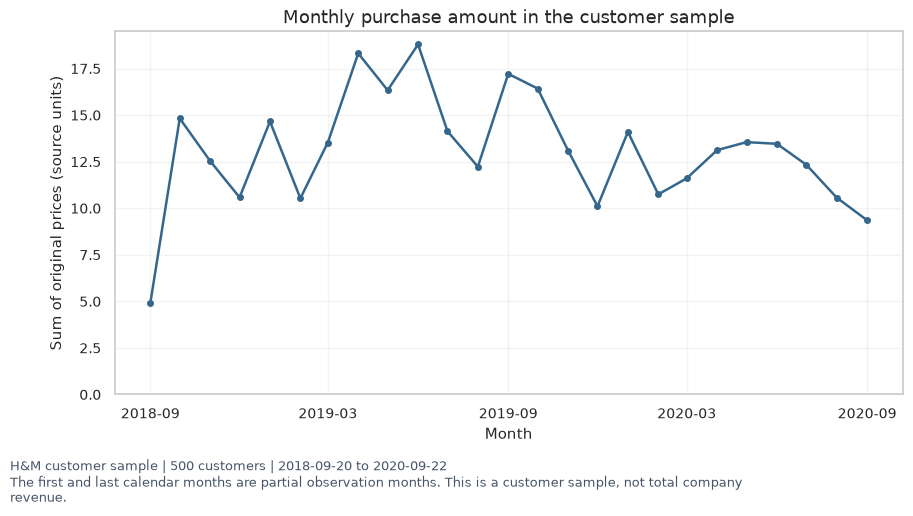

내부 관측 월 중 2019-06의 합계가 18.7954 원본 단위로 가장 크다. 첫·마지막 달은 부분 기간이다. 같은 고객 표본의 움직임이며 회사 전체 매출이나 계절성의 증거로 단정하지 않는다.

In [54]:
display(figures['06_monthly_line'])  # 과거 표본 기간의 월별 합계를 표시한다.
plt.close(figures['06_monthly_line'])  # 그림 메모리를 정리한다.
monthly = analyzer.monthly_summary()  # 같은 시계열 집계를 확인한다.
complete_months = monthly.iloc[1:-1]  # 양 끝의 부분 관측 월을 빼고 내부 달을 비교한다.
peak = complete_months['amount'].idxmax()  # 내부 관측 달 중 가장 큰 합계를 찾는다.
display(Markdown(f"내부 관측 월 중 {peak:%Y-%m}의 합계가 {complete_months.loc[peak, 'amount']:.4f} 원본 단위로 가장 크다. 첫·마지막 달은 부분 기간이다. 같은 고객 표본의 움직임이며 회사 전체 매출이나 계절성의 증거로 단정하지 않는다."))  # 숫자 근거와 부분 기간 한계를 붙인다.

<br><br><br>

## 🟢 7. 근거가 있는 제안 세 가지  

아래 제안은 관측 결과로 설계한 가설이다. 실제 메시지를 보내거나 실험을 실행하지 않았다. 기대 효과는 검증할 목표이며 측정된 개선율이 아니다.  

In [55]:
for insight in business_insights(analyzer):  # 같은 집계에서 만든 세 제안을 보여 준다.
    display(Markdown(f"### 🟡 {insight['title']}\n\n- 근거: {insight['evidence']}\n- 실행: {insight['action']}\n- 검증: {insight['validation']}"))  # 각 제안에 수치·행동·반증 조건을 함께 제시한다.

### 🟡 최근 고빈도·고금액 고객의 관계 유지

- 근거: Recent buyers / Frequent & high spending 183명은 고객의 36.6%, 표본 구매 금액 합계의 80.2%다.
- 실행: 이 그룹에 구매 상품군과 연관된 추천을 소규모 대조 실험으로 제공한다. 목표는 재구매 유지이며 개선율은 아직 측정하지 않았다.
- 검증: 통제군과 비교한 재구매율·순이익, 반품·할인·동의 정보를 추가로 확인해야 한다. 높은 금액만으로 추천의 효과가 입증되지는 않는다.

### 🟡 상대적으로 오래 미구매한 고가치 고객의 재방문 검증

- 근거: No recent purchase / Frequent & high spending 57명의 평균 미구매 간격은 342.4일이고 표본 금액 비중은 11.1%다.
- 실행: 이 그룹을 대상으로 재방문 안내와 미제공 대조군을 비교하는 실험을 설계한다. 목표는 재방문율 개선이며 실제 개선율은 아직 측정하지 않았다. 과거 구매일 기준 분류이며 현재 실제 이탈 고객이라고 단정하지 않는다.
- 검증: 관측 종료 뒤 구매 기록과 수신 동의, 재방문 이유가 필요하다. 관측 기간 종료 때문에 재방문을 못 본 것일 수도 있다.

### 🟡 그 외 최근 구매 고객의 후속 구매 기회

- 근거: Recent buyers / Less frequent or lower spending 68명의 평균 구매 빈도는 4.75행, 평균 금액 합계는 0.1205 원본 가격 단위다.
- 실행: 이 그룹에 상품 사용 정보와 관련 상품 추천을 제공하는 실험을 설계하고 다음 구매일까지의 기간을 비교한다. 목표는 후속 구매까지의 기간 단축이며 실제 효과는 아직 측정하지 않았다. 신규 회원이라는 근거가 없으므로 신규 고객이라고 부르지 않는다.
- 검증: 가입일·반품·배송 만족도와 후속 구매 관측 기간이 필요하다. 단순한 계절 구매 고객이라면 추천 효과가 없을 수 있다.

<br><br><br>

## 🟢 8. 결과 검증과 로컬 저장  

구매 행·고객 수·금액 합계가 전처리 중 달라지지 않았는지 확인한다. 실제 고객 번호가 있는 CSV는 Git에서 제외된 data/processed에만 저장한다.  

In [56]:
assert len(analyzer.df) == len(analyzer.raw_df) == audit['rows']  # 상품·이미지 연결 후 거래가 줄거나 늘지 않아야 한다.
assert np.allclose(analyzer.df['amount'], analyzer.raw_df['amount'])  # RFM 입력 금액은 원본과 같아야 한다.
assert np.isclose(analyzer.rfm['monetary'].sum(), analyzer.df['amount'].sum())  # 고객 금액 합계와 거래 금액 합계를 대조한다.
assert analyzer.segment_summary()['customers'].sum() == audit['customers']  # 모든 고객이 정확히 한 그룹에 속해야 한다.
assert audit['rfm']['segment_count'] == 4 and audit['images']['decoded_products'] >= 100  # 과제 분류 수와 이미지 준비 규모를 확인한다.
assert analyzer.correlations()['pearson_r'].notna().sum() >= 2  # 최소 두 변수 쌍을 실제로 계산했어야 한다.

# ✅ pipeline.py > DataAnalyzer Class > save_processed 함수 사용
analyzer.save_processed(root / 'data/processed')  # 다시 만들 수 있는 로컬 분석 결과를 저장한다.

print('필수 결과 검사 통과. 고객별 자료는 data/processed에만 저장됨.')  # 개인정보 없이 검증 상태를 알린다.

필수 결과 검사 통과. 고객별 자료는 data/processed에만 저장됨.


<br><br><br>

## 🟢 배운 내용과 다음 단계  

표본 연결에서 시작해 결측치 대치·IQR·실제 이미지 배열·글 특성·통계·네 고객 그룹·여섯 차트·세 가지 제안까지 실행했다. 선택한 고객 전체 구매 이력은 보존했지만 표본이 전체 고객을 대표한다고 검증한 것은 아니다.  

분석 결과를 설명할 때는 수치, 분석 대상 수, 단위, 한계를 같이 말한다. 반품·수량·주문 번호·확인된 통화·현재 구매 이력이 없으므로 이익·주문 횟수·현재 이탈·예측 성과를 계산했다고 주장하지 않는다. 이미지가 있는 100개 상품의 결론은 그 범위로 제한한다.  

재현: 프로젝트 최상위에서 `uv sync --locked` 후 `uv run --locked --python 3.11 main.py`를 실행한다. 노트북 재실행은 `uv run --locked --python 3.11 scripts/run_notebook.py`다. 명령의 모든 부분은 학습 문서에서 풀이한다. 실행 후 `reports/analysis.md`, 그래프 여섯 개, `data/processed` 결과를 확인한다.  

필수 분석 이후 보너스 과제나 추가 실험을 검토할 수 있다. 컨테이너는 선택 학습이며 이미지를 직접 받고 실행하는 단계부터 진행한다.  